In [1]:
import os
import pandas as pd
import subprocess
from datetime import datetime
from datetime import date
import statsmodels.api as sm
import numpy as np

In [2]:
project_id = os.environ.get('GOOGLE_CLOUD_PROJECT')
print(project_id)

dataset_id='C2024Q3R9'

dataset=!wb resolve --id {dataset_id} 
dataset_str = dataset[0]
print(dataset_str)
workspace_bucket = f"gs://cloned-mybucket{project_id}"
os.environ["WORKSPACE_BUCKET"] = workspace_bucket

# Set environment variable
os.environ['WORKSPACE_CDR'] = dataset_str
CDR_version = os.getenv("WORKSPACE_CDR")
dataset = %env WORKSPACE_CDR


wb-chirpy-leek-1262
wb-silky-artichoke-2408.C2024Q3R9


In [3]:
import json
ancestry_file = "/home/jupyter/workspace/vwb-aou-datasets-controlled/v8/wgs/short_read/snpindel/aux/ancestry/echo_v4_r2.ancestry_preds.tsv"
ancestry = pd.read_csv(ancestry_file, sep="\t", converters={"pca_features": json.loads})

In [4]:
pc = pd.DataFrame([pd.Series(x) for x in ancestry.pca_features])
pc.columns = ['PC_{}'.format(x+1) for x in pc.columns]

ancestry = pd.concat([ancestry, pc], axis=1)

In [5]:
import pandas
import os

# This query represents dataset "WGS_all_demographics" for domain "person" and was generated for All of Us Controlled Tier Dataset v7
dataset_80927560_person_sql = """
    SELECT
        person.person_id,
        p_gender_concept.concept_name as gender,
        person.birth_datetime as date_of_birth,
        p_race_concept.concept_name as race,
        p_ethnicity_concept.concept_name as ethnicity,
        p_sex_at_birth_concept.concept_name as sex_at_birth 
    FROM
        `""" + os.environ["WORKSPACE_CDR"] + """.person` person 
    LEFT JOIN
        `""" + os.environ["WORKSPACE_CDR"] + """.concept` p_gender_concept 
            ON person.gender_concept_id = p_gender_concept.concept_id 
    LEFT JOIN
        `""" + os.environ["WORKSPACE_CDR"] + """.concept` p_race_concept 
            ON person.race_concept_id = p_race_concept.concept_id 
    LEFT JOIN
        `""" + os.environ["WORKSPACE_CDR"] + """.concept` p_ethnicity_concept 
            ON person.ethnicity_concept_id = p_ethnicity_concept.concept_id 
    LEFT JOIN
        `""" + os.environ["WORKSPACE_CDR"] + """.concept` p_sex_at_birth_concept 
            ON person.sex_at_birth_concept_id = p_sex_at_birth_concept.concept_id  
    WHERE
        person.PERSON_ID IN (
            SELECT
                distinct person_id  
            FROM
                `""" + os.environ["WORKSPACE_CDR"] + """.cb_search_person` cb_search_person  
            WHERE
                cb_search_person.person_id IN (
                    SELECT
                        person_id 
                    FROM
                        `""" + os.environ["WORKSPACE_CDR"] + """.cb_search_person` p 
                    WHERE
                        has_whole_genome_variant = 1 
                ) 
            )"""

demo_patients = pandas.read_gbq(
    dataset_80927560_person_sql,
    dialect="standard",
    use_bqstorage_api=("BIGQUERY_STORAGE_API_ENABLED" in os.environ),
    progress_bar_type="tqdm_notebook")


/tmp/ipykernel_13702/2369922946.py:44: FutureWarning: read_gbq is deprecated and will be removed in a future version. Please use pandas_gbq.read_gbq instead: https://pandas-gbq.readthedocs.io/en/latest/api.html#pandas_gbq.read_gbq
  demo_patients = pandas.read_gbq(


Downloading:   0%|          |

In [6]:
#Clean up missing data
# Make dummies
demo_patients = pd.get_dummies(demo_patients.set_index(['person_id'])).reset_index()

#combine into unknown race
columns_to_consider = ['race_I prefer not to answer', 'race_None Indicated', 'race_None of these', 'race_PMI: Skip']
demo_patients['race_unknown'] = demo_patients[columns_to_consider].any(axis=1).astype(int)
demo_patients = demo_patients.drop(columns=columns_to_consider)

#combine into unknown ethncity 
columns_to_consider = ['ethnicity_What Race Ethnicity: Race Ethnicity None Of These', 'ethnicity_PMI: Skip', 'ethnicity_PMI: Prefer Not To Answer']
demo_patients['ethnicity_unknown'] = demo_patients[columns_to_consider].any(axis=1).astype(int)
demo_patients = demo_patients.drop(columns=columns_to_consider)

#combine into other sex
columns_to_consider = ['sex_at_birth_I prefer not to answer', 'sex_at_birth_PMI: Skip', 'sex_at_birth_Intersex', 'sex_at_birth_Sex At Birth: Sex At Birth None Of These']
demo_patients['sex_other'] = demo_patients[columns_to_consider].any(axis=1).astype(int)
demo_patients = demo_patients.drop(columns=columns_to_consider)

#combine into other gender
columns_to_consider = ['gender_PMI: Skip', 'gender_Not man only, not woman only, prefer not to answer, or skipped', 'gender_Gender Identity: Non Binary', 
                       'gender_I prefer not to answer', "gender_Gender Identity: Transgender", "gender_Gender Identity: Additional Options"]
demo_patients['gender_other'] = demo_patients[columns_to_consider].any(axis=1).astype(int)
demo_patients = demo_patients.drop(columns=columns_to_consider)

# Create a new column 'Sex/gender'
conditions = [
    (demo_patients['sex_at_birth_Female'] & demo_patients['gender_Female']),
    (demo_patients['sex_at_birth_Male'] & demo_patients['gender_Male'])
]

choices = ['Cis_female', 'Cis_male']

demo_patients['SexGender'] = np.select(conditions, choices, default='SGM')
#SGM: Sex or Gender Minority

demo_patients.dropna()

#remove unneeded columns
demo_patients=demo_patients.drop(['gender_Female', 'gender_Male',
                                             'sex_other', 'gender_other', "sex_at_birth_Female", 
                                              "sex_at_birth_Male", "ethnicity_Not Hispanic or Latino",
                                             "ethnicity_unknown"], axis=1)

#rename columns for simplicity 
demo_patients=demo_patients.rename(columns={"race_Black or African American": "Black",
                                                       "race_Middle Eastern or North African": "Mid",
                                                       "race_More than one population": "Multiple",
                                                       "race_Native Hawaiian or Other Pacific Islander": "PI",
                                                       "race_White": "White",
                                                       "ethnicity_Hispanic or Latino": "His",
                                                       "race_Asian": "Asian",
                                                       "race_American Indian or Alaska Native": "AIAN"})



In [7]:
demo_patients["date_of_birth"] = demo_patients["date_of_birth"].astype(str) 
demo_patients["date_of_birth"] = demo_patients["date_of_birth"].str[0:10]

def calculate_age(born):
    born = datetime.strptime(born, "%Y-%m-%d").date()
    today = date.today()
    return today.year - born.year - ((today.month, today.day) < (born.month, born.day))

demo_patients['age_today'] = demo_patients['date_of_birth'].apply(calculate_age)

In [8]:
demo_patients.shape

(414830, 13)

In [9]:
#clean up ancestry
ancestry=ancestry.rename(columns={"research_id": "person_id"})
ancestry=ancestry.iloc[:, [0, 1] + list(range(5, 21))]

#join with ancestry
demo_patients = pd.merge(demo_patients, ancestry, on="person_id", how="inner") # now merge to other ehr covariates # amended 04/17/2020

In [10]:
demo_patients['AIAN'].value_counts()


AIAN
False    409076
True       5754
Name: count, dtype: int64

# Disability

In [11]:
# This query represents dataset "all_participant_demographics" for domain "survey" and was generated for All of Us Controlled Tier Dataset v8
dataset_04882547_survey_sql = """
    SELECT
        answer.person_id,
        answer.survey_datetime,
        answer.survey,
        answer.question_concept_id,
        answer.question,
        answer.answer_concept_id,
        answer.answer,
        answer.survey_version_concept_id,
        answer.survey_version_name  
    FROM
        `""" + os.environ["WORKSPACE_CDR"] + """.ds_survey` answer   
    WHERE
        (
            question_concept_id IN (SELECT
                DISTINCT concept_id                         
            FROM
                `""" + os.environ["WORKSPACE_CDR"] + """.cb_criteria` c                         
            JOIN
                (SELECT
                    CAST(cr.id as string) AS id                               
                FROM
                    `""" + os.environ["WORKSPACE_CDR"] + """.cb_criteria` cr                               
                WHERE
                    concept_id IN (1586134)                               
                    AND domain_id = 'SURVEY') a 
                    ON (c.path like CONCAT('%', a.id, '.%'))                         
            WHERE
                domain_id = 'SURVEY'                         
                AND type = 'PPI'                         
                AND subtype = 'QUESTION')
        )"""

survey_df = pandas.read_gbq(
    dataset_04882547_survey_sql,
    dialect="standard",
    use_bqstorage_api=("BIGQUERY_STORAGE_API_ENABLED" in os.environ),
    progress_bar_type="tqdm_notebook")

/tmp/ipykernel_13702/2881787554.py:36: FutureWarning: read_gbq is deprecated and will be removed in a future version. Please use pandas_gbq.read_gbq instead: https://pandas-gbq.readthedocs.io/en/latest/api.html#pandas_gbq.read_gbq
  survey_df = pandas.read_gbq(
/opt/conda/envs/jupyter/lib/python3.12/site-packages/pandas/io/gbq.py:207: LargeResultsWarning: Recommendation: Your results are 1.4 GiB. Consider using BigQuery DataFrames (https://bit.ly/bigframes-intro)to process large results with pandas compatible APIs with transparent SQL pushdown to BigQuery engine. This provides an opportunity to save on costs and improve performance. Please reach out to bigframes-feedback@google.com with any questions or concerns. To disable this message, run warnings.simplefilter('ignore', category=pandas_gbq.exceptions.LargeResultsWarning)
  return pandas_gbq.read_gbq(


Downloading:   0%|          |

In [12]:
# select disability and pivot table
selected_questions = [903573, 903574, 903578, 903577, 903576, 903575, 1585889, 1585940, 1586135, 1585852, 43528428]


all_merged_data = demo_patients.copy()

for question_id in selected_questions:
    # Filter the dataset to include only the current question
    filtered_data = survey_df[survey_df['question_concept_id'] == question_id]
    
    # Remove duplicates and keep the first occurrence of each person_id
    filtered_data = filtered_data.drop_duplicates(subset='person_id', keep='first')
    
    # Rename the 'answer' column to the question number
    filtered_data = filtered_data.rename(columns={'answer': str(question_id)})
    
    # Filter the columns by selecting 'person_id' and the current question number
    filtered_data = filtered_data[['person_id', str(question_id)]]
    
    # Merge the filtered data with the person_df DataFrame
    all_merged_data = pd.merge(all_merged_data, filtered_data, on='person_id', how='left')
    
all_merged_data = all_merged_data.rename(columns={
    '903573': 'Deaf',
    '903574': 'Blind',
    '903575': 'Diff_concentrating',
    '903576': 'Diff_walkorclimb',
    '903577': 'Diff_dressorbathe',
    '903578': 'Diff_errandsalone',
    '1585889' : 'number_living',
    '1585940' : 'education',
    '1586135' : 'where_born',
    '1585852' : 'military',
    '43528428' : 'healthcare'   
    
})

In [13]:
#disability
all_merged_data['Deaf'] = all_merged_data['Deaf'].replace({'Deaf: No':0,'Deaf: Yes':1, 
                                                   'Deaf: Prefer Not To Answer':0,'PMI: Skip':0})
all_merged_data['Blind'] = all_merged_data['Blind'].replace({'Blind: No':0,'Blind: Yes':1,'PMI: Skip':0,
                                                     'Blind: Prefer Not To Answer':0})

all_merged_data['Diff_concentrating'] = all_merged_data['Diff_concentrating'].replace({'Difficulty Concentrating: No':0,
                                                                               'Difficulty Concentrating: Yes': 1,
                                                                               'PMI: Skip':0,
                                                                               'Difficulty Concentrating: Prefer Not To Answer':0})
    
all_merged_data['Diff_walkorclimb'] = all_merged_data['Diff_walkorclimb'].replace({'Walking Climbing: No':0,'Walking Climbing: Yes':1,
                                                                           'PMI: Skip':0,'Walking Climbing: Prefer Not To Answer':0})
    
all_merged_data['Diff_dressorbathe'] = all_merged_data['Diff_dressorbathe'].replace({'Dressing Bathing: No':0,'PMI: Skip':0,
                                                                             'Dressing Bathing: Yes':1,
                                                                             'Dressing Bathing: Prefer Not To Answer':0})
    
all_merged_data['Diff_errandsalone'] = all_merged_data['Diff_errandsalone'].replace({'Errands Alone: No':0,'PMI: Skip':0,
                                                                             'Errands Alone: Yes':1,
                                                                             'Errands Alone: Prefer Not To Answer':0})

#binary disability variable
def sum_na(row):
    if row.isna().any():
        return np.nan
    else:
        return 1 if row.sum() > 0 else 0

all_merged_data['disabled'] = all_merged_data[['Deaf', 'Blind', 'Diff_concentrating', 'Diff_walkorclimb',
                                       'Diff_dressorbathe', 'Diff_errandsalone']].apply(sum_na, axis=1)
all_merged_data.drop(['Deaf', 'Blind', 'Diff_concentrating', 'Diff_walkorclimb',
                      'Diff_dressorbathe', 'Diff_errandsalone'], axis=1, inplace=True)

all_merged_data['disabled'] = all_merged_data['disabled'].replace({0: 'No', 1: 'Yes', np.nan: 'Missing'})
print(all_merged_data['disabled'].value_counts())


/tmp/ipykernel_13702/209002115.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  all_merged_data['Deaf'] = all_merged_data['Deaf'].replace({'Deaf: No':0,'Deaf: Yes':1,
/tmp/ipykernel_13702/209002115.py:4: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  all_merged_data['Blind'] = all_merged_data['Blind'].replace({'Blind: No':0,'Blind: Yes':1,'PMI: Skip':0,
/tmp/ipykernel_13702/209002115.py:7: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitl

disabled
No         198583
Missing    138292
Yes         77955
Name: count, dtype: int64


# LGBTQIA+

In [14]:
#select 1585838 The Basics: Sexual Orientation
# 'selected_sex_or' is a list of question concept IDs relating to sexual orientation.
selected_sex_or = [1585899]

# 'filtered_sex_or' filters the survey DataFrame to include only the questions in 'selected_sex_or'.
filtered_sex_or = survey_df[survey_df['question_concept_id'].isin(selected_sex_or)]

# Rename the 'answer' column to 'sexual_orientation' for clarity.
filtered_sex_or = filtered_sex_or.rename(columns={'answer': 'sexual_orientation'})

# Select 'person_id' and 'sexual_orientation' columns for the analysis.
filtered_sex_or= filtered_sex_or[['person_id','sexual_orientation']]

# 'sex_answer_map' is a dictionary that maps the specific answer values to general categories.
sex_answer_map = {
    'Sexual Orientation: Straight': 'Straight',
    'Sexual Orientation: Lesbian': 'Lesbian',
    'Sexual Orientation: Gay': 'Gay',
    'Sexual Orientation: Bisexual': 'Bisexual',
    'Sexual Orientation: None': 'None',
    'PMI: Skip': 'Skip',
    'PMI: Prefer Not To Answer': 'PNA'
}

# Apply the mapping to the 'sexual_orientation' column.
filtered_sex_or['sexual_orientation'] = filtered_sex_or['sexual_orientation'].replace(sex_answer_map)

# Create dummy variables for each category in 'sexual_orientation'.
# This transforms categorical variable into binary (0 or 1) columns for each category.
dummies = pd.get_dummies(filtered_sex_or['sexual_orientation'], prefix='so')
filtered_sex_or = pd.concat([filtered_sex_or, dummies], axis=1)

# Group by 'person_id' and sum the dummy variables.
# The summing here would account for each category per person.
sex_df_sum = filtered_sex_or.groupby('person_id')[['so_Bisexual', 'so_Gay', 'so_Lesbian', 'so_None', 'so_PNA', 'so_Skip', 'so_Straight']].sum().reset_index()

# Calculate the number of distinct sexual orientations per person.
# If the sum of binary variables for 'Bisexual', 'Gay', 'Lesbian', 'Straight' is greater than 1, the person is classified as 'Multiple'.
sex_df_sum['Multiple'] = sex_df_sum[['so_Bisexual', 'so_Gay', 'so_Lesbian', 'so_Straight']].sum(axis=1).apply(lambda x: 1 if x > 1 else 0)

# Based on the created dummy variable columns, assign the corresponding 'sexual_orientation'.
# If a person has 'Multiple' as 1, their sexual orientation is 'Multiple'.
# If not, the other conditions check which of the sexual orientation categories have a 1 and assigns that category.
# If none of the categories is 1, the orientation is marked as 'Other'.
sex_df_sum['sexual_orientation'] = np.where(sex_df_sum['Multiple'] == 1, 'Queer',
                    np.where((sex_df_sum['Multiple'] == 0) & (sex_df_sum['so_PNA'] == 1), 'PNA or Skip',
                        np.where((sex_df_sum['Multiple'] == 0) & (sex_df_sum['so_Skip'] == 1), 'PNA or Skip',
                            np.where((sex_df_sum['Multiple'] == 0) & (sex_df_sum['so_Straight'] == 1), 'Straight',
                                np.where((sex_df_sum['Multiple'] == 0) & (sex_df_sum['so_Gay'] == 1), 'Queer',
                                    np.where((sex_df_sum['Multiple'] == 0) & (sex_df_sum['so_Lesbian'] == 1), 'Queer',
                                        np.where((sex_df_sum['Multiple'] == 0) & (sex_df_sum['so_None'] == 1), 'Queer',
                                            np.where((sex_df_sum['Multiple'] == 0) & (sex_df_sum['so_Bisexual'] == 1), 'Queer', 'Other'))))))))

# Select 'person_id' and 'sexual_orientation' columns for the merged dataset.
sex_df_sum= sex_df_sum[['person_id','sexual_orientation']]

# Merge the 'sex_df_sum' DataFrame with 'all_merged_data' DataFrame using 'person_id' as the key.
all_merged_data =pd.merge(all_merged_data, sex_df_sum, on='person_id')

all_merged_data['LGBTQIA'] = ((all_merged_data['SexGender'] == 'SGM') | (all_merged_data['sexual_orientation'] == 'Queer')).astype(int)



In [15]:
print(all_merged_data['sexual_orientation'].value_counts())

sexual_orientation
Straight       363703
Queer           40555
PNA or Skip     10572
Name: count, dtype: int64


# Income

In [16]:
survey_income = survey_df[survey_df['question_concept_id']==1585375]

# Rename the 'answer' column to 'income' for clarity.
survey_income = survey_income.rename(columns={'answer': 'income'})

survey_income['basics_survey_datetime'] = survey_income['survey_datetime']

# Select columns for the analysis.
survey_income = survey_income[['person_id', 'income', 'basics_survey_datetime']]

all_merged_data = pd.merge(all_merged_data, survey_income, on='person_id', how='left')

In [17]:
#This block of code is selecting and processing data related to income.

# This code block is mapping the various income levels to a more simplified classification.
# 'Annual Income: more 200k' and 'Annual Income: 150k 200k' are mapped to '>150k'.
# 'Annual Income: 100k 150k' is mapped to '100k-150k'.
# 'Annual Income: 75k 100k' and 'Annual Income: 50k 75k' are mapped to '50k-100k'.
# 'Annual Income: 35k 50k', 'Annual Income: 25k 35k', 'Annual Income: 10k 25k' and 'Annual Income: less 10k' are mapped to '<50k'.
# 'PMI: Prefer Not To Answer' and 'PMI: Skip' are mapped to 'Skip or PNA' - probably indicating the person chose to skip the question or preferred not to answer.
all_merged_data['income_grouped'] = all_merged_data['income'].replace({"Annual Income: more 200k": ">150k",
                                             "Annual Income: 150k 200k": ">150k",
                                             "Annual Income: 100k 150k": "100k-150k",
                                             "Annual Income: 75k 100k": "50k-100k",
                                             "Annual Income: 50k 75k": "50k-100k",
                                             "Annual Income: 35k 50k": "<50k",
                                             "Annual Income: 25k 35k": "<50k",
                                             "Annual Income: 10k 25k": "<50k",
                                             "Annual Income: less 10k": "<50k",
                                             'PMI: Prefer Not To Answer':'Skip or PNA',
                                             'PMI: Skip':'Skip or PNA' })

In [18]:
all_merged_data['income_grouped'].value_counts()/len(all_merged_data['income_grouped'])*100

income_grouped
<50k           38.551214
Skip or PNA    20.202493
50k-100k       19.103006
>150k          11.677314
100k-150k      10.465974
Name: count, dtype: float64

In [19]:
# Define the mapping
income_mapping = {
    'Annual Income: less 10k': 5000,
    'Annual Income: 10k 25k': 12500,
    'Annual Income: 25k 35k': 30000,
    'Annual Income: 35k 50k': 42500,
    'Annual Income: 50k 75k': 62500,
    'Annual Income: 75k 100k': 87500,
    'Annual Income: 100k 150k': 125000,
    'Annual Income: 150k 200k': 175000,
    'Annual Income: more 200k': 225000
}

# Map values, anything not in the mapping becomes np.nan
all_merged_data['income'] = all_merged_data['income'].map(lambda x: income_mapping.get(x, np.nan))

In [20]:
all_merged_data['number_living'] = pd.to_numeric(all_merged_data['number_living'], errors='coerce')

all_merged_data['number_living'] = all_merged_data['number_living'] + 1

# Education

In [21]:
# This code block is mapping various education levels to a more simplified classification.
# 'Highest Grade: Nine Through Eleven', 'Highest Grade: Five Through Eight', 'Highest Grade: One Through Four' and 'Highest Grade: Never Attended' 
# are all mapped to 'Less than high school degree or equivalent'.
# 'Highest Grade: Advanced Degree' and 'Highest Grade: College Graduate' are mapped to 'College graduate or advanced degree'.
# 'Highest Grade: Twelve Or GED' remains 'Twelve or GED'.
# 'Highest Grade: College One to Three' remains 'College One to Three'.
# 'PMI: Prefer Not To Answer' and 'PMI: Skip' are mapped to 'Skip or PNA'.
all_merged_data['education'] = all_merged_data['education'].replace({'Highest Grade: Nine Through Eleven': 'Less than high school degree or equivalent',
                                                'Highest Grade: Five Through Eight': 'Less than high school degree or equivalent',
                                                'Highest Grade: One Through Four': 'Less than high school degree or equivalent',
                                                'Highest Grade: Never Attended': 'Less than high school degree or equivalent',
                                                'Highest Grade: Advanced Degree': 'Advanced degree',
                                                'Highest Grade: College Graduate':'College graduate',
                                                'Highest Grade: Twelve Or GED':'Twelve or GED',
                                                'Highest Grade: College One to Three': 'College One to Three',
                                                'PMI: Prefer Not To Answer':'Skip or PNA','PMI: Skip':'Skip or PNA'})

# Born

In [22]:
all_merged_data['where_born'] = all_merged_data['where_born'].replace({'Birthplace: USA': 'USA',
                                                'PMI: Other': 'elsewhere',
                                                'PMI: Skip': 'Skip'})

# Military

In [23]:
all_merged_data['military'] = all_merged_data['military'].replace({'Active Duty Serve Status: No': 'No',
                                                'Active Duty Serve Status: Yes': 'Yes',
                                                'PMI: Skip': 'Skip or PNA',
                                                 'PMI: Prefer Not To Answer': 'Skip or PNA'})
all_merged_data['military'].value_counts()

military
No             367469
Yes             41426
Skip or PNA      5893
Name: count, dtype: int64

# Healthcare Coverage

In [24]:
all_merged_data['healthcare'] = all_merged_data['healthcare'].replace({'Insurance Type Update: Employer Or Union': 'Employer Or Union',
                                                'Insurance Type Update: Medicaid': 'Medicaid',
                                                'Insurance Type Update: Medicare': 'Medicare',
                                                'Insurance Type Update: Purchased': 'Purchased ',
                                                'Insurance Type Update: VA': 'VA or Military',
                                                'Insurance Type Update: Military':'VA or Military',
                                                'Insurance Type Update: None': 'None',                     
                                                'Insurance Type Update: Other Health Plan':'Other',
                                                'Insurance Type Update: Indian': 'Other',
                                                'Invalid':'Other',
                                                                       'PMI: Skip':'Skip'})

all_merged_data['healthcare'].value_counts()

healthcare
Employer Or Union    141158
Medicaid              85697
Medicare              73428
Purchased             24718
VA or Military        16369
Other                 15189
Skip                   4083
None                   2512
Name: count, dtype: int64

# EHR filtering

In [25]:
# first query from condition occurrence to get number of distinct codes and ehr length
query="""SELECT person_id, min(condition_start_date) as min_cond_date,max(condition_start_date)as max_cond_date,
COUNT(DISTINCT condition_concept_id) as cond_code_cnt, COUNT(DISTINCT visit_occurrence_id) as num_cond_visits
FROM `"""+CDR_version+""".condition_occurrence` WHERE condition_start_date >='1880-01-01'
GROUP BY person_id """

ehr_covariate=pd.read_gbq(query, dialect="standard")
# EHR Length is a bit subtle here. Observation date is a little tricky because birthdate is used in observation. 
# What we need to do is take the relevant codes from observation and find the minimum and maximum dates overall
query = ("""
    SELECT distinct person_id, min(observation_date) as min_obs_date, max(observation_date) as max_obs_date, 
    COUNT(DISTINCT observation_concept_id) as observation_code_cnt, COUNT(DISTINCT visit_occurrence_id) as num_obs_visits
    FROM 
        (SELECT DISTINCT person_id, observation_source_concept_id, observation_source_value, 
        observation_date, observation_concept_id, visit_occurrence_id
            FROM `"""+ str(CDR_version) +""".observation`) AS obs
            INNER JOIN 
            (SELECT DISTINCT concept_id, concept_name, concept_code, vocabulary_id 
                    FROM `"""+str(CDR_version)+""".concept`
                    where (vocabulary_id ='ICD9CM') or 
                (vocabulary_id ='ICD10CM')) as concept 
                on concept.concept_id = obs.observation_source_concept_id
    group by person_id
    """)
observation_code_dates = pd.read_gbq(query, dialect="standard")
    # note, this procedure takes into consideration NaTs, so if a person didn't have an observation code, it will
    # automatically take the minimum condition occurrence date.
ehr_covariate_plus = pd.merge(observation_code_dates, ehr_covariate, on="person_id", how = 'outer')

/tmp/ipykernel_13702/2649791578.py:7: FutureWarning: read_gbq is deprecated and will be removed in a future version. Please use pandas_gbq.read_gbq instead: https://pandas-gbq.readthedocs.io/en/latest/api.html#pandas_gbq.read_gbq
  ehr_covariate=pd.read_gbq(query, dialect="standard")
/tmp/ipykernel_13702/2649791578.py:25: FutureWarning: read_gbq is deprecated and will be removed in a future version. Please use pandas_gbq.read_gbq instead: https://pandas-gbq.readthedocs.io/en/latest/api.html#pandas_gbq.read_gbq
  observation_code_dates = pd.read_gbq(query, dialect="standard")


In [26]:
# Convert dates to string and remove '-'
ehr_covariate_plus['min_obs_date'] = ehr_covariate_plus['min_obs_date'].astype(str).str.replace('-', '', regex=False)
ehr_covariate_plus['min_cond_date'] = ehr_covariate_plus['min_cond_date'].astype(str).str.replace('-', '', regex=False)
ehr_covariate_plus['max_obs_date'] = ehr_covariate_plus['max_obs_date'].astype(str).str.replace('-', '', regex=False)
ehr_covariate_plus['max_cond_date'] = ehr_covariate_plus['max_cond_date'].astype(str).str.replace('-', '', regex=False)

# Convert columns to integers safely

# Convert columns to integers safely
ehr_covariate_plus["min_date"] = ehr_covariate_plus[["min_obs_date", "min_cond_date"]].min(axis=1).astype(int)

# Apply function to compute max_date
ehr_covariate_plus["max_date"] = ehr_covariate_plus[["max_obs_date", "max_cond_date"]].max(axis=1)
ehr_covariate_plus.loc[ehr_covariate_plus["max_date"] == "NaT", "max_date"] = ehr_covariate_plus["max_cond_date"]
ehr_covariate_plus.loc[ehr_covariate_plus["max_date"] == "NaT", "max_date"] = ehr_covariate_plus["max_obs_date"]
ehr_covariate_plus["max_date"] = ehr_covariate_plus["max_date"].astype(int)

#put back into datetime data type
ehr_covariate_plus["min_date"]=pd.to_datetime(ehr_covariate_plus['min_date'], format='%Y%m%d',)
ehr_covariate_plus["max_date"]=pd.to_datetime(ehr_covariate_plus['max_date'], format='%Y%m%d',)

#Make covariates
ehr_covariate_plus["ehr_length"]=(ehr_covariate_plus['max_date']-ehr_covariate_plus['min_date']).apply(lambda x:x.days)
ehr_covariate_plus["relative_health"]=ehr_covariate_plus["observation_code_cnt"]+ehr_covariate_plus["cond_code_cnt"]
ehr_covariate_plus["record_depth"]=ehr_covariate_plus["num_obs_visits"]+ehr_covariate_plus["num_cond_visits"]
ehr_covariate_plus = ehr_covariate_plus.drop(columns = ["min_obs_date","min_cond_date","max_obs_date","max_cond_date",
                    "cond_code_cnt","observation_code_cnt", "num_obs_visits", "num_cond_visits" ])
ehr_covariate_plus["visit_frequency"]=ehr_covariate_plus['record_depth']/ehr_covariate_plus['ehr_length']


In [27]:
demo_patients_merge = pd.merge(all_merged_data, ehr_covariate_plus, on="person_id", how="inner") # now merge to other ehr covariates # amended 04/17/2020


def calculate_age(date_of_birth, max_date):
    date_of_birth = date_of_birth.date()
    max_date = max_date.date()
    age = max_date.year - date_of_birth.year
    if (max_date.month, max_date.day) < (date_of_birth.month, date_of_birth.day):
        age -= 1
    return age

demo_patients_merge["date_of_birth"] = pd.to_datetime(demo_patients_merge["date_of_birth"])
demo_patients_merge["max_date"] = pd.to_datetime(demo_patients_merge["max_date"])

demo_patients_merge["age_at_last_event"] = demo_patients_merge.apply(lambda row: calculate_age(row["date_of_birth"], row["max_date"]), axis=1)


In [28]:
# This snippet assumes you run setup first

# This code saves your dataframe into a csv file in a "data" folder in Google Bucket

# Replace df with THE NAME OF YOUR DATAFRAME
my_dataframe = demo_patients_merge 

# Replace 'test.csv' with THE NAME of the file you're going to store in the bucket (don't delete the quotation marks)
destination_filename = 'all_WGS_demographics.csv'

########################################################################
##
################# DON'T CHANGE FROM HERE ###############################
##
########################################################################

# save dataframe in a csv file in the same workspace as the notebook
my_dataframe.to_csv(destination_filename, index=False)

# get the bucket name
my_bucket = os.getenv('WORKSPACE_BUCKET')

# copy csv file to the bucket
args = ["gsutil", "cp", f"./{destination_filename}", f"{my_bucket}/data/"]
output = subprocess.run(args, capture_output=True)

# print output from gsutil
output.stderr


b'Copying file://./all_WGS_demographics.csv [Content-Type=text/csv]...\n/ [0 files][    0.0 B/159.4 MiB]                                                \r==> NOTE: You are uploading one or more large file(s), which would run\nsignificantly faster if you enable parallel composite uploads. This\nfeature can be enabled by editing the\n"parallel_composite_upload_threshold" value in your .boto\nconfiguration file. However, note that if you do this large files will\nbe uploaded as `composite objects\n<https://cloud.google.com/storage/docs/composite-objects>`_,which\nmeans that any user who downloads such objects will need to have a\ncompiled crcmod installed (see "gsutil help crcmod"). This is because\nwithout a compiled crcmod, computing checksums on composite objects is\nso slow that gsutil disables downloads of composite objects.\n\nCaught ResumableUploadStartOverException for upload of file://./all_WGS_demographics.csv.\nChecking that bucket cloned-mybucketwb-chirpy-leek-1262 exists befo

In [29]:
demo_patients_merge.shape

(289191, 48)

In [30]:
len(demo_patients_merge[demo_patients_merge["SexGender"]=="SGM"])

7644

In [31]:
#remove those with insufficent EHR data
demo_patients_merge = demo_patients_merge[demo_patients_merge['record_depth'] > 2].dropna(subset=['record_depth'])
demo_patients_merge=demo_patients_merge[demo_patients_merge['ehr_length']>1095].dropna(subset=['ehr_length'])
demo_patients_merge.shape

(135611, 48)

In [32]:
demo_patients['AIAN'].value_counts()


AIAN
False    409076
True       5754
Name: count, dtype: int64

In [33]:
demo_patients_merge.columns

Index(['person_id', 'date_of_birth', 'AIAN', 'Asian', 'Black', 'Mid',
       'Multiple', 'PI', 'White', 'His', 'race_unknown', 'SexGender',
       'age_today', 'ancestry_pred', 'PC_1', 'PC_2', 'PC_3', 'PC_4', 'PC_5',
       'PC_6', 'PC_7', 'PC_8', 'PC_9', 'PC_10', 'PC_11', 'PC_12', 'PC_13',
       'PC_14', 'PC_15', 'PC_16', 'number_living', 'education', 'where_born',
       'military', 'healthcare', 'disabled', 'sexual_orientation', 'LGBTQIA',
       'income', 'basics_survey_datetime', 'income_grouped', 'min_date',
       'max_date', 'ehr_length', 'relative_health', 'record_depth',
       'visit_frequency', 'age_at_last_event'],
      dtype='object')

<Axes: >

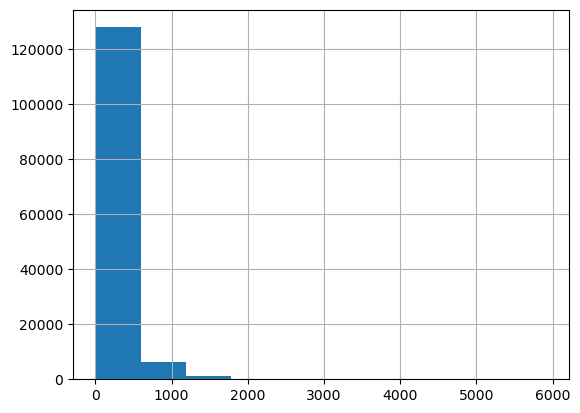

In [34]:
demo_patients_merge['record_depth'].hist()

In [35]:
from scipy.stats.mstats import winsorize
demo_patients_merge['record_depth'] = demo_patients_merge['record_depth'].astype(np.float64)
# Winsorize the data, capping 1% of values on both ends
demo_patients_merge['record_depth_winsorized'] = winsorize(demo_patients_merge['record_depth'], limits=[0.0, 0.01])


<Axes: >

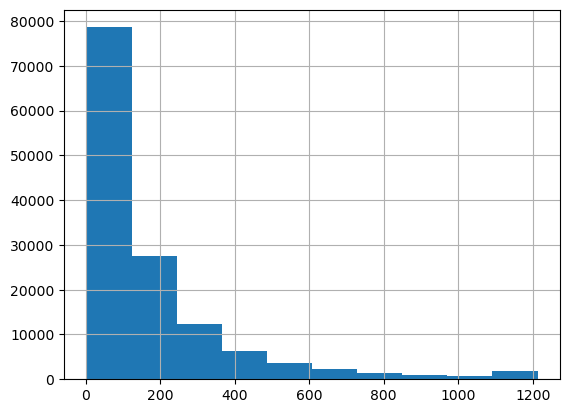

In [36]:
demo_patients_merge['record_depth_winsorized'].hist()

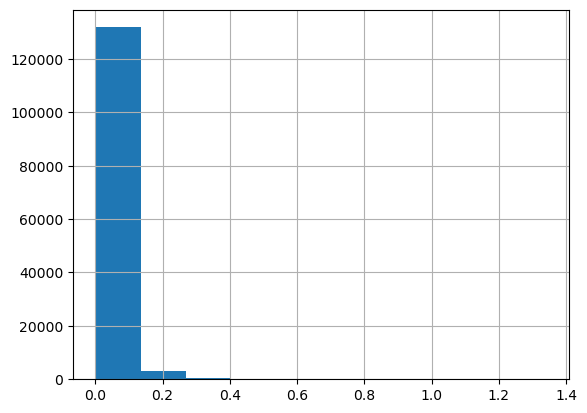

In [37]:
demo_patients_merge['visit_frequency'].hist()
demo_patients_merge['visit_frequency'] = demo_patients_merge['visit_frequency'].astype(np.float64)
# Winsorize the data, capping 1% of values on both ends
demo_patients_merge['visit_frequency_winsorized'] = winsorize(demo_patients_merge['visit_frequency'], limits=[0.0, 0.01])


<Axes: >

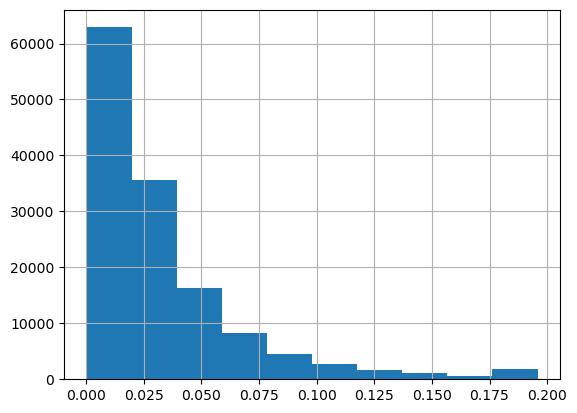

In [38]:
demo_patients_merge['visit_frequency_winsorized'].hist()

In [39]:
#Remove those <18 
demo_patients_merge["age_at_last_event"].describe()
demo_patients_merge = demo_patients_merge[demo_patients_merge['age_at_last_event'] >= 18].dropna(subset=['age_at_last_event'])

demo_patients_merge['age2'] = demo_patients_merge["age_at_last_event"]^2

In [40]:
# This snippet assumes you run setup first

# This code saves your dataframe into a csv file in a "data" folder in Google Bucket

# Replace df with THE NAME OF YOUR DATAFRAME
my_dataframe = demo_patients_merge  

# Replace 'test.csv' with THE NAME of the file you're going to store in the bucket (don't delete the quotation marks)
destination_filename = 'Demographic_and_ancestry_covariates.csv'

########################################################################
##
################# DON'T CHANGE FROM HERE ###############################
##
########################################################################

# save dataframe in a csv file in the same workspace as the notebook
my_dataframe.to_csv(destination_filename, index=False)

# get the bucket name
my_bucket = os.getenv('WORKSPACE_BUCKET')

# copy csv file to the bucket
args = ["gsutil", "cp", f"./{destination_filename}", f"{my_bucket}/data/"]
output = subprocess.run(args, capture_output=True)

# print output from gsutil
output.stderr


b'Copying file://./Demographic_and_ancestry_covariates.csv [Content-Type=text/csv]...\n/ [0 files][    0.0 B/ 80.1 MiB]                                                \rCaught ResumableUploadStartOverException for upload of file://./Demographic_and_ancestry_covariates.csv.\nChecking that bucket cloned-mybucketwb-chirpy-leek-1262 exists before retrying upload...\nDeleted tracker file /home/jupyter/.gsutil/tracker-files/upload_TRACKER_d6d76feb075dd66fe00306ff3aa351e81a4b68f6.es.csv__JSON.url for resumable upload of file://./Demographic_and_ancestry_covariates.csv before retrying.\nBucketNotFoundException: 404 gs://cloned-mybucketwb-chirpy-leek-1262 bucket does not exist.\n'